In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RESULTS_FOLDER = Path("../../results/RF_uci_results")
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)

# Load the features made by build_features.py
data = pd.read_csv("../../data/processed/uci/uci_features.csv")
LABEL_COLUMNS = ["split", "activity", "participant", "position", "platform", "recording_id"]

train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

X_train, y_train = train.drop(columns=LABEL_COLUMNS), train["activity"]
X_test, y_test = test.drop(columns=LABEL_COLUMNS), test["activity"]

print(f"Train: {X_train.shape}   Test: {X_test.shape}")

Train: (3285, 84)   Test: (1387, 84)


In [6]:
rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)

predictions = rf.predict(X_test)
print("Model: Random Forest Classifier")
print("Dataset: UCI")
print(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
print(f"Macro F1: {f1_score(y_test, predictions, average='macro'):.3f}\n")
print(classification_report(y_test, predictions, digits=3))

Model: Random Forest Classifier
Dataset: UCI
Accuracy: 0.885
Macro F1: 0.885

                    precision    recall  f1-score   support

           walking      0.873     0.911     0.892       496
walking_downstairs      0.943     0.831     0.884       420
  walking_upstairs      0.856     0.907     0.880       471

          accuracy                          0.885      1387
         macro avg      0.891     0.883     0.885      1387
      weighted avg      0.888     0.885     0.885      1387



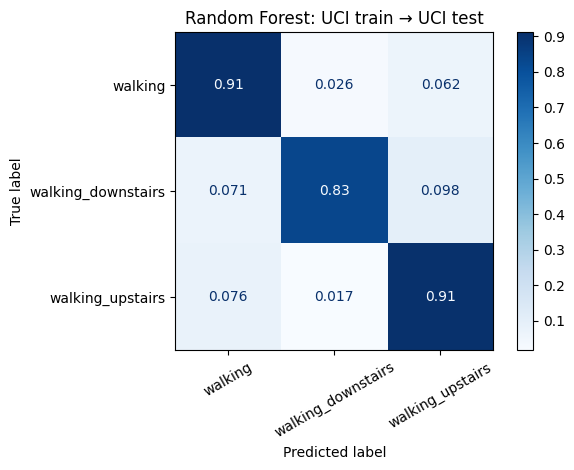

In [7]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, normalize="true",
                                        cmap="Blues", xticks_rotation=30)
plt.title("Random Forest: UCI train → UCI test")
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "RF_uci_confusion_matrix.png", dpi=150)
plt.show()

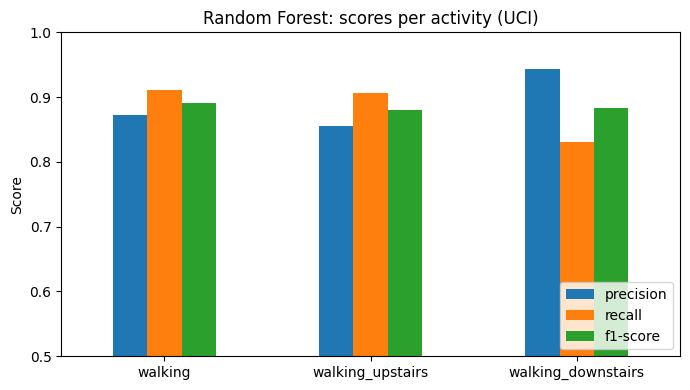

In [12]:
report = pd.DataFrame(classification_report(y_test, predictions, output_dict=True)).T
per_activity = report.loc[["walking", "walking_upstairs", "walking_downstairs"], ["precision", "recall", "f1-score"]]

per_activity.plot(kind="bar", figsize=(7, 4), ylim=(0.5, 1), rot=0)
plt.title("Random Forest: scores per activity (UCI)")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "RF_uci_per_activity.png", dpi=150)
plt.show()